# LeetCode #165: Compare Version Numbers

https://leetcode.com/problems/compare-version-numbers/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Split & Compare ★ | O(n+m) | O(n+m) |
| Two Pointers | O(n+m) | O(1) |

## Understanding the Methods
### Split & Compare ★
Split both version strings by '.', convert each part to integer, and compare element by element. If one version has fewer parts, treat missing parts as 0. Return -1, 0, or 1 based on comparisons.

### Two Pointers
Use two pointers to parse integer values from each string without splitting, advancing past '.' separators. Same comparison logic but avoids allocating split arrays.

## Solutions
### C#

In [ ]:
public class Solution {
    public int CompareVersion(string version1, string version2) {
        var v1 = version1.Split('.');
        var v2 = version2.Split('.');
        int n = Math.Max(v1.Length, v2.Length);
        for (int i = 0; i < n; i++) {
            int a = i < v1.Length ? int.Parse(v1[i]) : 0;
            int b = i < v2.Length ? int.Parse(v2[i]) : 0;
            if (a < b) return -1;
            if (a > b) return 1;
        }
        return 0;
    }
}

### Python

In [ ]:
from itertools import zip_longest

class Solution:
    def compareVersion(self, version1: str, version2: str) -> int:
        v1 = list(map(int, version1.split('.')))
        v2 = list(map(int, version2.split('.')))
        for a, b in zip_longest(v1, v2, fillvalue=0):
            if a < b: return -1
            if a > b: return 1
        return 0

### Go

In [ ]:
package main

import (
    "fmt"
    "strconv"
    "strings"
)

func compareVersion(version1 string, version2 string) int {
    v1 := strings.Split(version1, ".")
    v2 := strings.Split(version2, ".")
    n := len(v1)
    if len(v2) > n { n = len(v2) }
    for i := 0; i < n; i++ {
        a, b := 0, 0
        if i < len(v1) { a, _ = strconv.Atoi(v1[i]) }
        if i < len(v2) { b, _ = strconv.Atoi(v2[i]) }
        if a < b { return -1 }
        if a > b { return 1 }
    }
    return 0
}

func main() {
    fmt.Println(compareVersion("1.01", "1.001")) // 0
    fmt.Println(compareVersion("1.0", "1.0.0"))  // 0
    fmt.Println(compareVersion("0.1", "1.1"))    // -1
}

### Rust

In [ ]:
pub struct Solution;

impl Solution {
    pub fn compare_version(version1: String, version2: String) -> i32 {
        let v1: Vec<i32> = version1.split('.').map(|s| s.parse().unwrap()).collect();
        let v2: Vec<i32> = version2.split('.').map(|s| s.parse().unwrap()).collect();
        let n = v1.len().max(v2.len());
        for i in 0..n {
            let a = v1.get(i).copied().unwrap_or(0);
            let b = v2.get(i).copied().unwrap_or(0);
            if a < b { return -1; }
            if a > b { return 1; }
        }
        0
    }
}

## Example Scenarios

### 1. Common Case — Compare Segment by Segment
**Input:** `version1 = "1.2"`, `version2 = "1.10"`
Split into revisions $[1,2]$ and $[1,10]$. First segments tie ($1=1$); second segments decide: $2 < 10$, so return $-1$.

### 2. Slightly Complex — Leading Zeros Ignored
**Input:** `version1 = "1.01"`, `version2 = "1.001"`
Parsing to integers drops leading zeros: $[1,1]$ vs $[1,1]$. Every segment is equal, so the result is $0$.

### 3. Edge Case: Time Factor — Unequal Segment Counts
**Input:** `version1 = "1.0"`, `version2 = "1.0.0"`
Iterate over $\max(2,3)=3$ positions. The missing third revision of `version1` is treated as $0$, matching $0$, so return $0$.

### 4. Edge Case: Space Factor — First Revision Decides
**Input:** `version1 = "0.1"`, `version2 = "1.1"`
The very first comparison $0 < 1$ settles it immediately; no later segments matter. Return $-1$.

### 5. Almost-Impossible but Plausible — Many Trailing Segments
**Input:** `version1 = "1.0.0.0.1"`, `version2 = "1"`
`version2` pads to $[1,0,0,0,0]$. Segments tie until the last, where $1 > 0$, so return $1$.


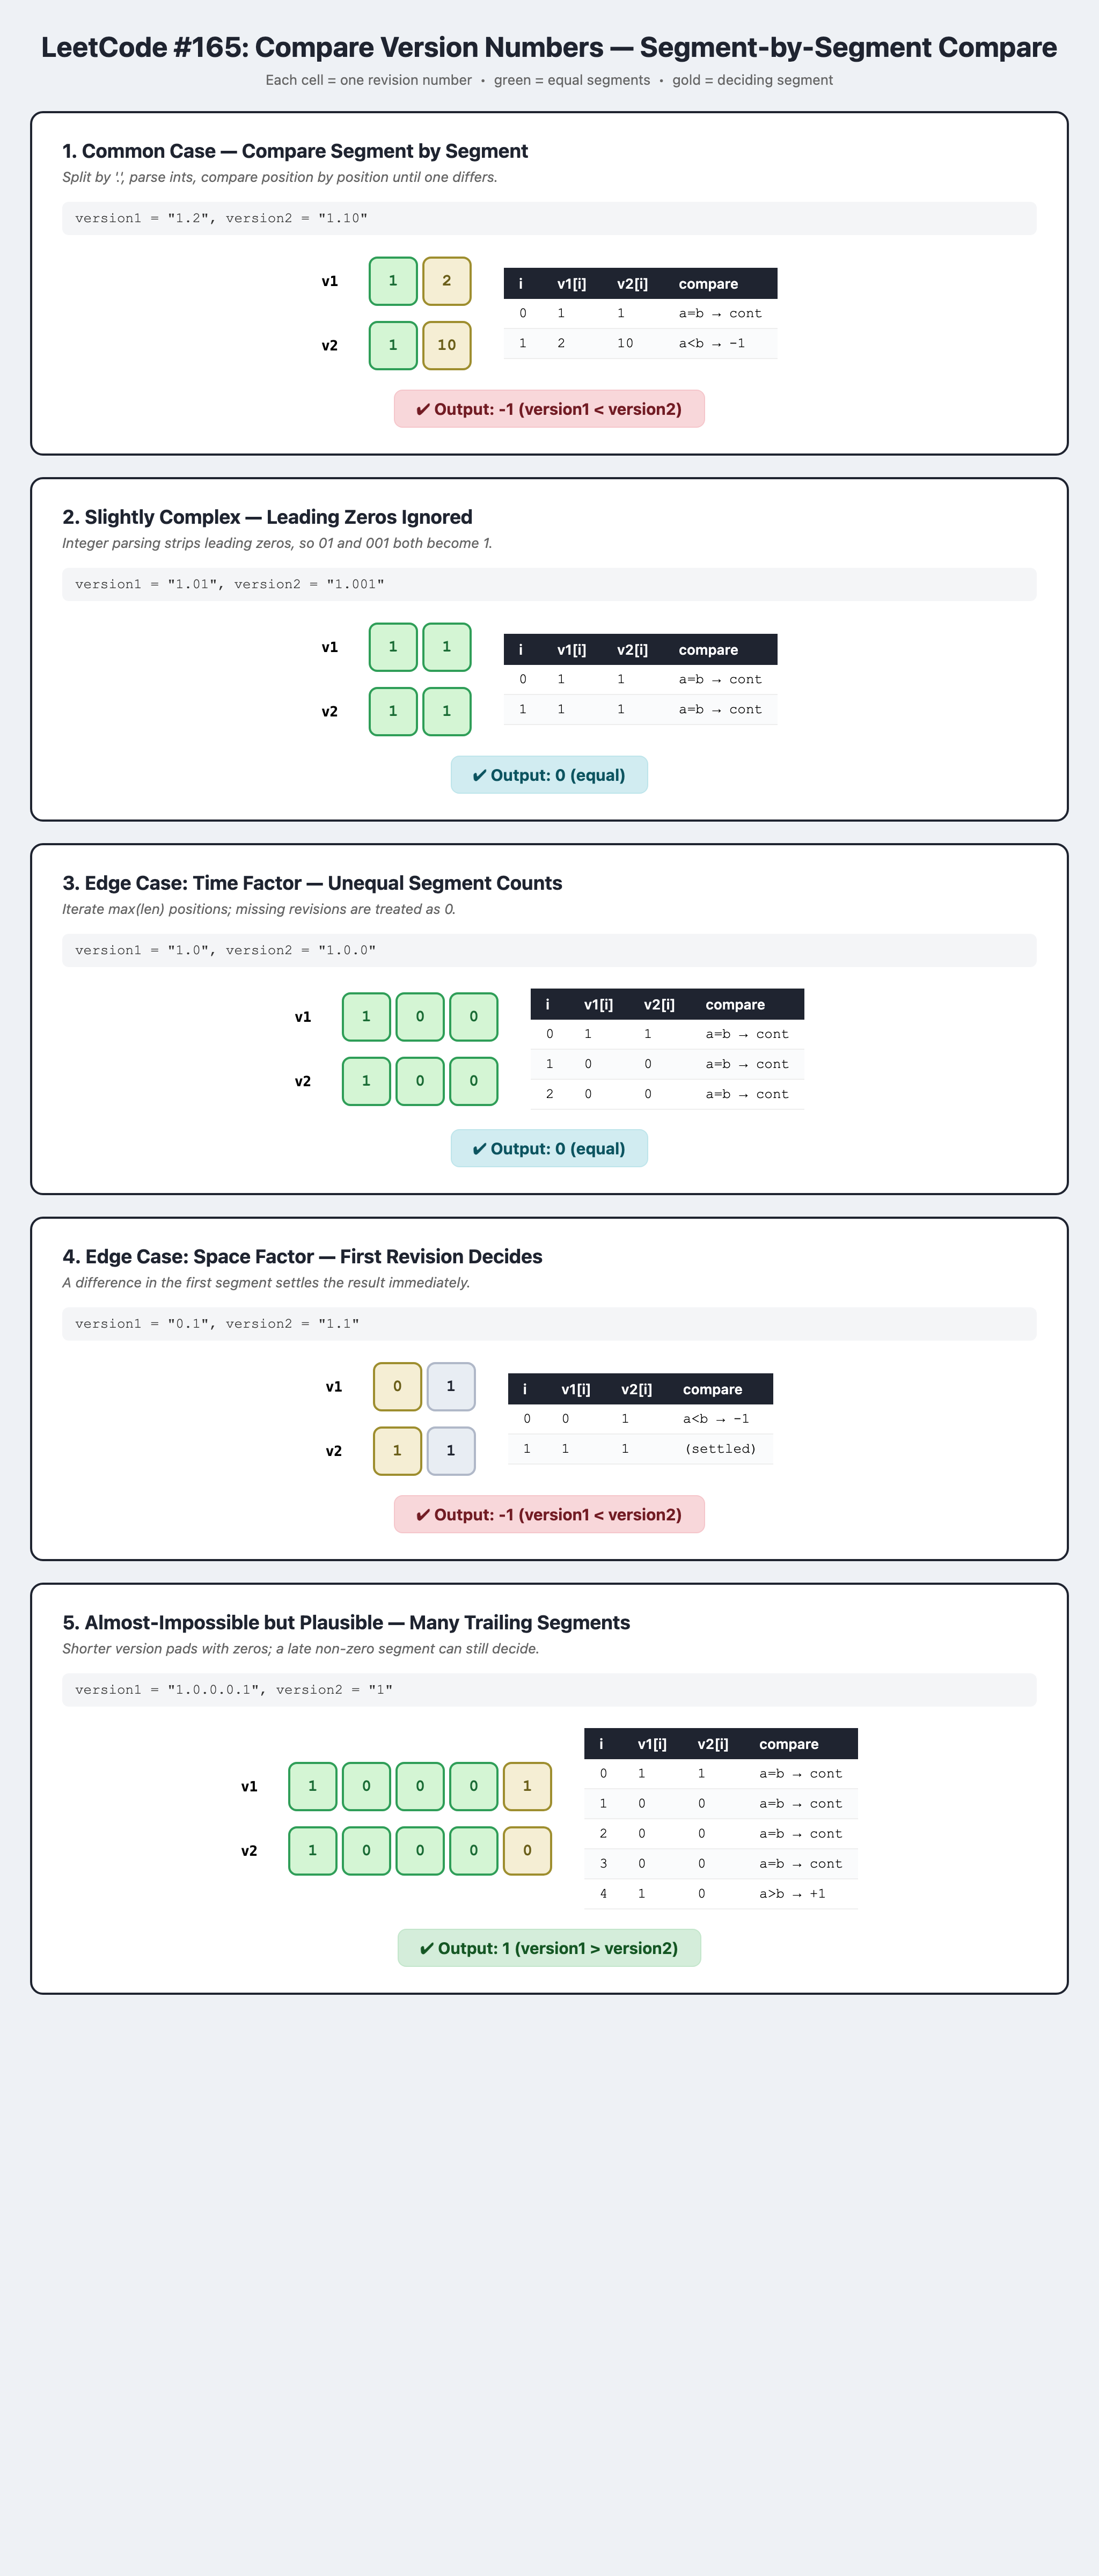